In [3]:
%pylab inline
import os
import pandas as pd
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import sim_analysis_utilities as utilities
import smatch
if True:
    aname='/home/xiangchong/work/gw_ipmu/work/COSMOS/cosmos_leauthaud_2007/COSMOS_ACS_catalog/acs_clean_only.fits'
    dbDir='./wrkDir/database/s19-COSMOS/wcut/'
    outDir      =   './wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/others/'
else:
    aname='/work/xiangchong.li/work/COSMOS/cosmos_leauthaud_2007/COSMOS_ACS_catalog/acs_clean_only.fits'

Populating the interactive namespace from numpy and matplotlib


# 3 catalogs

* HSC wdie_depth_best catalog (S16A sim)
* HSC wdie_depth_median catalog (S16A sim)
* HSC wdie_depth_worst catalog (S16A sim)

In [4]:
coscat=pyfits.getdata(aname)
coscat=coscat[coscat['mu_class']<3]
bcat=pyfits.getdata(os.path.join(dbDir,'COSMOS_WIDE_DEPTH_BEST.fits'))
mcat=pyfits.getdata(os.path.join(dbDir,'COSMOS_WIDE_DEPTH_MEDIAN.fits'))
wcat=pyfits.getdata(os.path.join(dbDir,'COSMOS_WIDE_DEPTH_WORST.fits'))

In [15]:
def main(cat0,cat):
    ra=cat0['ALPHAPEAK_J2000']
    dec=cat0['DELTAPEAK_J2000']
    bmatch   =   smatch.match(cat['i_ra'],cat['i_dec'],0.6/3600.,ra,dec,maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field
    cmsk=np.zeros(len(ra),dtype=bool)
    cat0=cat0[bmatch['i2']]
    cat=cat[bmatch['i1']]
    print(len(cat0),len(cat))
    fmsk=(cat0['mu_class']==2) & (cat['i_extendedness_value']==1)
    mag=utilities.get_imag(cat)
    nb=9
    if True:
        bd=np.percentile(mag,np.linspace(0,100,nb))
    else:
        bd=np.linspace(np.min(mag),np.max(mag)+0.01,nb)
    out=np.zeros(nb-1)
    std=np.zeros(nb-1)
    for i in range(nb-1):
        msk=(mag>bd[i])&(mag<bd[i+1])
        fmski=fmsk[msk]
        out[i]=np.sum(fmski)/np.sum(msk)
        std[i]=np.sqrt(np.sum(fmski))/np.sum(msk)
    print(np.sum(fmsk)/len(cat0))
    magave=(bd[1:]+bd[:-1])/2.
    print(magave,out)
    return np.sum(fmsk)/len(cat0),magave,out,std

In [16]:
bb,ba,bo,be=main(coscat,bcat)
mm,ma,mo,me=main(coscat,mcat)
ww,wa,wo,we=main(coscat,wcat)

137578 137578
0.0018026137899954935
[18.82828641 22.25554562 22.93359017 23.37542057 23.7101692  23.98419702
 24.21750808 24.43157887] [0.00104669 0.00133744 0.00110484 0.00191894 0.00197709 0.00209339
 0.00255859 0.00238414]
129763 129763
0.002111541810839762
[18.77709198 22.21254778 22.89373708 23.340626   23.68023777 23.95943451
 24.20019579 24.42580652] [0.00104809 0.00104809 0.00147965 0.00191122 0.00240444 0.00332922
 0.0027127  0.00295931]
123821 123821
0.003028565429127531
[18.70705795 22.12685633 22.8163929  23.27254486 23.61965656 23.90474796
 24.15534687 24.40526676] [0.00155069 0.00167991 0.00252019 0.00277868 0.00290754 0.00348905
 0.00478129 0.00452284]


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


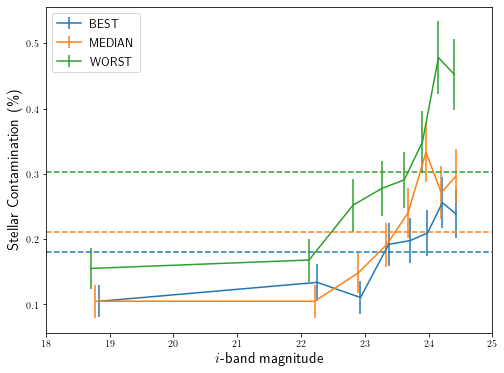

In [20]:
cm=plt.get_cmap('tab10')
xmin=18;xmax=25
ccp=np.linspace(xmin,xmax,30)
fig=plt.figure(figsize=(8,6))
plt.errorbar(ba,bo*100,be*100.,c=cm(0),label='BEST')
plt.plot(ccp,bb*np.ones(len(ccp))*100,'--',c=cm(0))
plt.errorbar(ma,mo*100,me*100.,c=cm(1),label='MEDIAN')
plt.plot(ccp,mm*np.ones(len(ccp))*100,'--',c=cm(1))
plt.errorbar(wa,wo*100,we*100.,c=cm(2),label='WORST')
plt.plot(ccp,ww*np.ones(len(ccp))*100,'--',c=cm(2))

plt.xlabel(r'$i$-band magnitude',fontsize=15)
plt.ylabel('Stellar Contamination (\%)',fontsize=15)
plt.xlim(xmin,xmax)

plt.legend(loc='upper left',fontsize=12)
fig.savefig(os.path.join(outDir,'stellar_contam.eps'))
fig.savefig(os.path.join(outDir,'stellar_contam.png'))

Text(0, 0.5, 'dec')

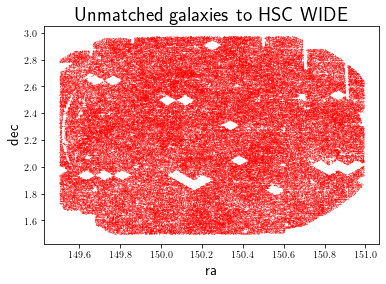

In [19]:
plt.scatter(bcat['i_ra'],bcat['i_dec'],s=0.01,c='red')
plt.title('Unmatched galaxies to HSC WIDE',fontsize=20)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)